# Глава 4. Наивный байесовский классификатор

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn import model_selection
from Lab01_data.utilities import visualize_classifier

In [12]:
# Входной файл, содержащий данные
input_file = 'Lab01_data/data_multivar_nb.txt'

# Загрузка данных из входного файла
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

Accuracy of Naive Bayes classifier = 99.75 %


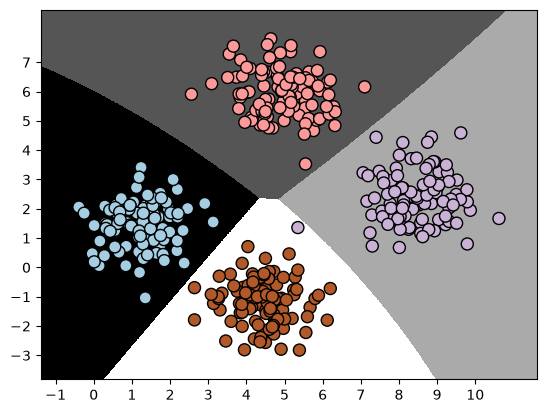

In [13]:
# Создание наивного байесовского классификатора
classifier = GaussianNB()

# Тренировка классификатора
classifier.fit(X, y)

# Прогнозирование значений для тренировочных данных
y_pred = classifier.predict(X)

# Вычисление качества классификатора
accuracy = 100.0 * (y == y_pred).sum() / X.shape[0]
print("Accuracy of Naive Bayes classifier =", round(accuracy, 2), "%")

# Визуализация результатов работы классификатора
visualize_classifier(classifier, X, y)

Accuracy of the new classifier = 100.0 %


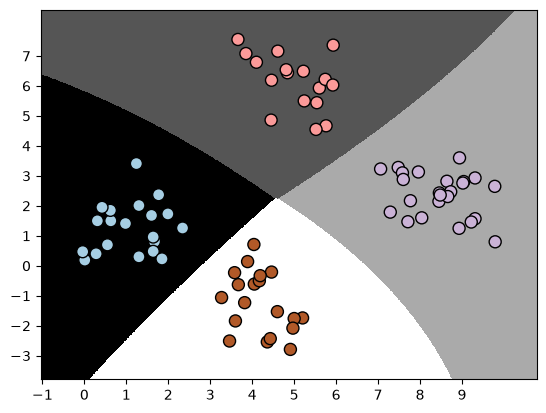

In [14]:
# Разбивка данных на обучающий и тестовый наборы
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, test_size=0.2, random_state=3)
classifier_new = GaussianNB()
classifier_new.fit(X_train, y_train)
y_test_pred = classifier_new.predict(X_test)

# Вычисление качества классификатора
accuracy = 100.0 * (y_test == y_test_pred).sum() / X_test.shape[0]
print("Accuracy of the new classifier =", round(accuracy, 2), "%")

# Визуализация работы классификатора
visualize_classifier(classifier_new, X_test, y_test)

In [ ]:
# Оценка показателей классификатора
num_folds = 3
accuracy_values = model_selection.cross_val_score(
    classifier, X, y, scoring='accuracy', cv=num_folds)
print("Accuracy: " + str(round(100*accuracy_values.mean(), 2)) + "%")

precision_values = model_selection.cross_val_score(
    classifier, X, y, scoring='precision_weighted', cv=num_folds)
print("Precision: " + str(round(100*precision_values.mean(), 2)) + "%")

recall_values = model_selection.cross_val_score(
    classifier, X, y, scoring='recall_weighted', cv=num_folds)
print("Recall: " + str(round(100*recall_values.mean(), 2)) + "%")

f1_values = model_selection.cross_val_score(
    classifier, X, y, scoring='f1_weighted', cv=num_folds)
print("F1: " + str(round(100*f1_values.mean(), 2)) + "%")

Accuracy: 99.75%
Precision: 99.76%
Recall: 99.75%
F1: 99.75%


: 